Downloaded expression_matrix.csv.gz: 6,455,713 bytes
Downloaded series_matrix.txt.gz: 4,080 bytes

Original expression matrix: (17500, 59)
Gene ID column: Gene
Sample columns preview: ['HC01', 'HC02', 'HC03', 'HC04', 'HC05', 'HC06', 'HC07', 'HC08', 'HC09', 'HC10', 'TC01']

GEO sample count: 58
group
SCI                38
Healthy_Control    10
Trauma_Control     10
Name: count, dtype: int64

Matrix sample columns: 58
Matched samples: 58
Unmatched matrix samples: []
Unmatched metadata samples: []

SAMPLE MATCHING SUCCESSFUL
Expression matrix: (17500, 58)

Final sample groups:
group
SCI                38
Healthy_Control    10
Trauma_Control     10
Name: count, dtype: int64


,metric,value
0,Genes after cleaning,17500
1,Samples,58
2,Missing expression values,0
3,Duplicate gene IDs,0


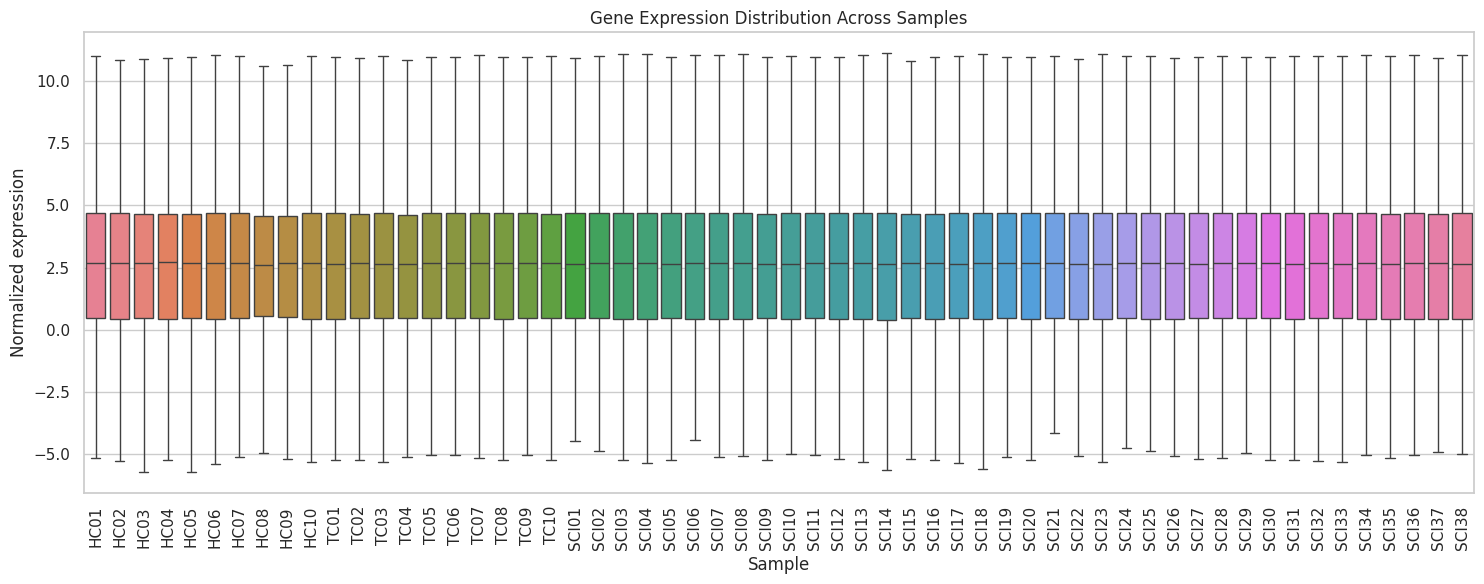

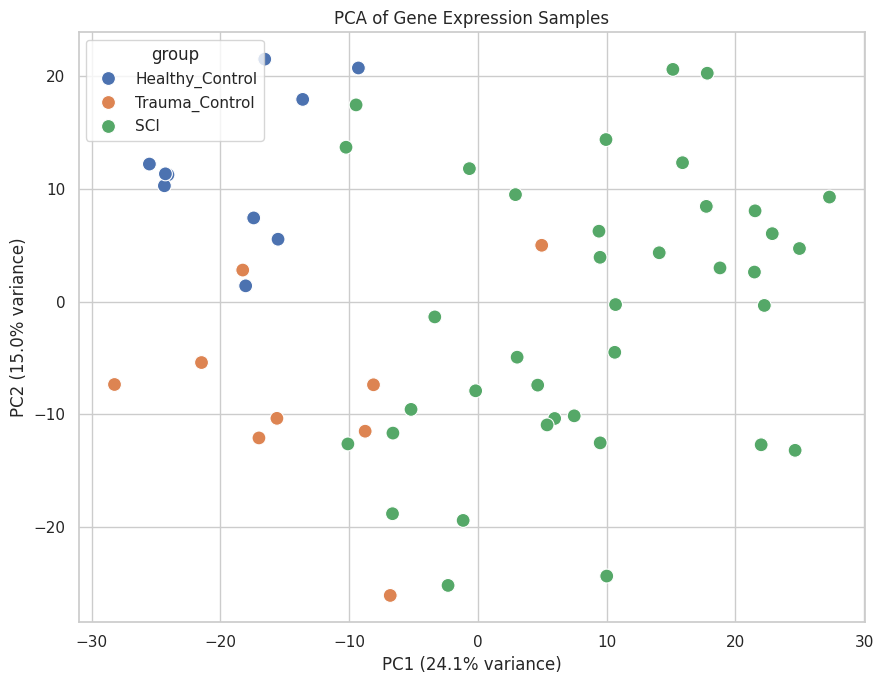


Top 15 results: SCI vs Healthy Controls


,gene_id,mean_SCI,mean_Healthy_Control,mean_difference,p_value,FDR,minus_log10_p
0,LOC100288778,1.962880,0.415637,1.547244,0.000711,3.661610e-15,3.147852
1,SLC7A6OS,2.221274,2.053847,0.167427,0.100927,2.224347e-14,0.995993
2,RGL3,-1.845094,-2.111290,0.266196,0.497961,1.818222e-13,0.302805
3,TMEM256,1.975831,1.530271,0.445559,0.053458,2.869645e-12,1.271985
4,NLRP9,-0.080674,-0.241554,0.160880,0.418291,3.127567e-12,0.378521
5,RCBTB1,4.191542,4.140795,0.050748,0.666414,3.127567e-12,0.176256
6,SH3D19,-0.698488,0.323937,-1.022425,0.001883,3.152880e-12,2.725063
7,SOCS2,1.799096,2.511790,-0.712694,0.003968,3.152880e-12,2.401433
8,TTK,0.383070,-0.403827,0.786896,0.053439,4.633618e-12,1.272143
9,ITGAX,8.691618,8.421253,0.270365,0.461074,6.240117e-12,0.336230


Genes with FDR < 0.05: 6566

Top 15 results: SCI vs Trauma Controls


,gene_id,mean_SCI,mean_Trauma_Control,mean_difference,p_value,FDR,minus_log10_p
0,FRRS1,2.349456,2.508562,-0.159105,0.310905,0.000009,0.507373
1,MND1,1.011233,0.303606,0.707626,0.008336,0.000016,2.079039
2,MIR573,-2.367684,-1.794264,-0.573420,0.170490,0.000016,0.768300
3,AHNAK2,-0.663519,0.706742,-1.370261,0.000964,0.000029,3.015875
4,P2RX5,0.855989,1.245211,-0.389222,0.177594,0.000030,0.750571
5,CTRL,1.987794,2.399384,-0.411591,0.026695,0.000043,1.573573
6,PGAP2,4.137761,4.254088,-0.116327,0.603344,0.000054,0.219435
7,TMEM30A,7.314643,7.373513,-0.058870,0.543139,0.000060,0.265089
8,EVL,4.785537,5.697378,-0.911842,0.000908,0.000071,3.041794
9,TMEM180,3.123974,2.964400,0.159574,0.387887,0.000072,0.411295


Genes with FDR < 0.05: 2438


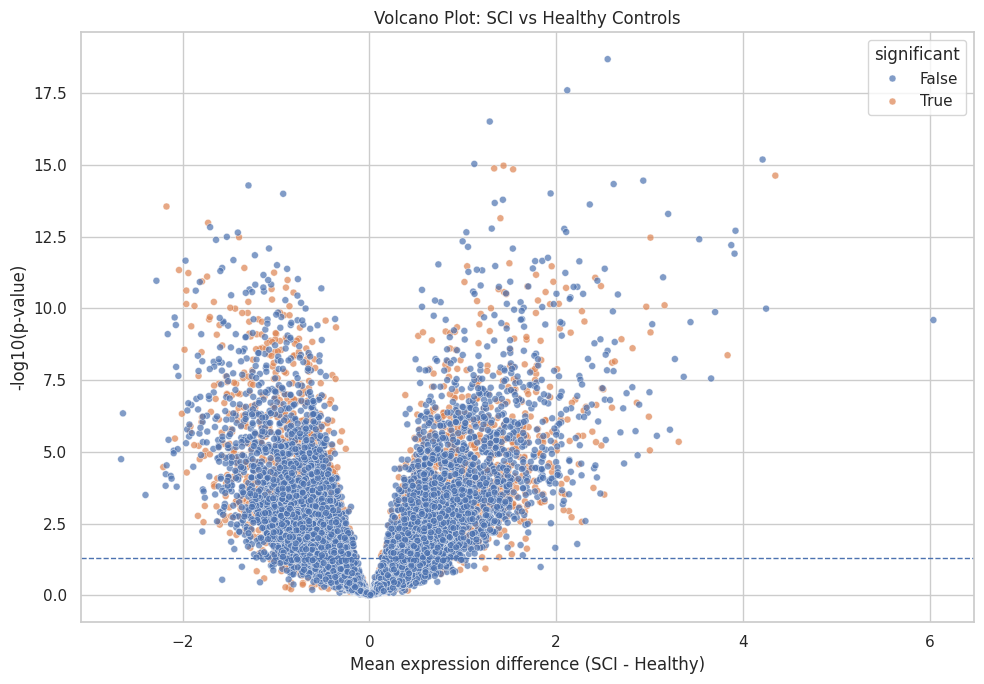

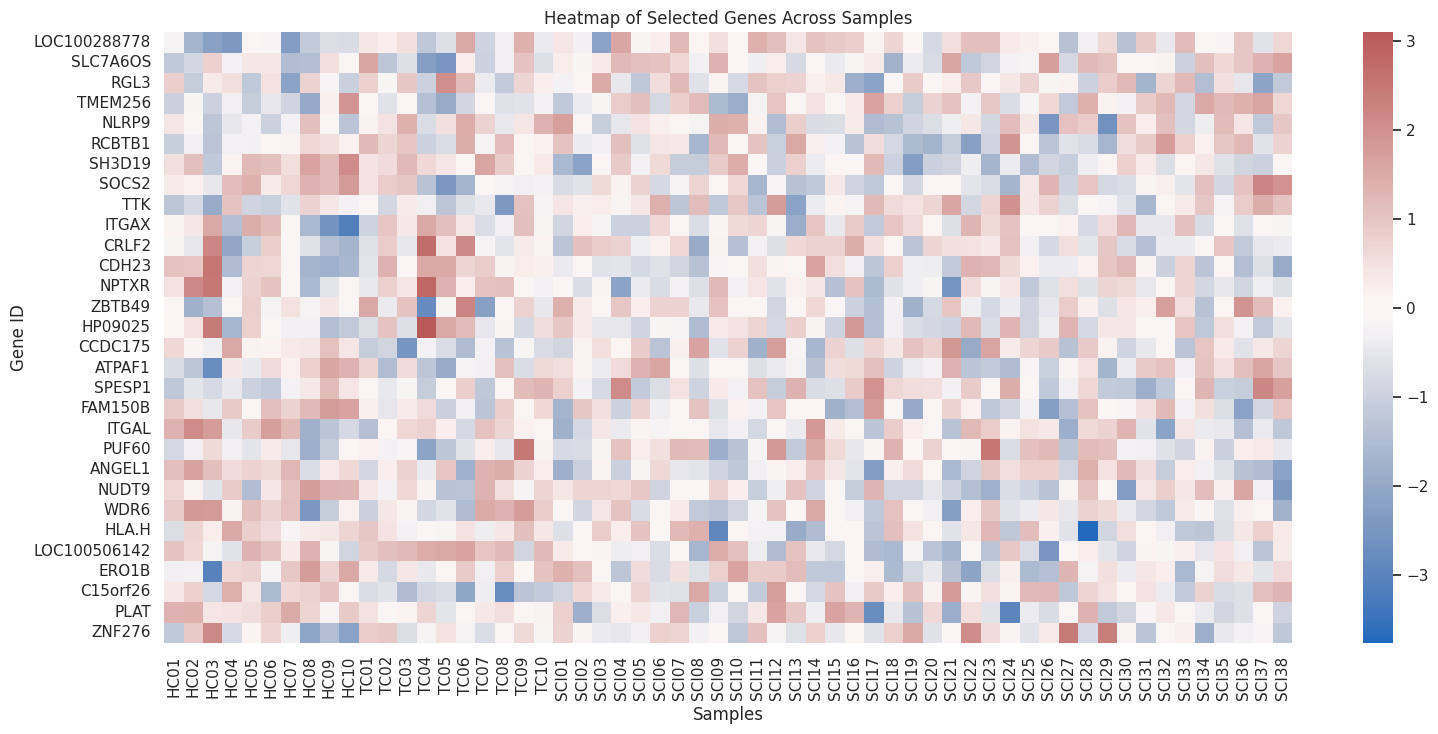


# Gene Expression Analysis in Spinal Cord Injury

## Dataset
- GEO accession: GSE151371
- Expression matrix: GEO normalized and batch-corrected matrix
- Genes after cleaning: 17500
- Samples analyzed: 58

## Sample groups
- Healthy controls: 10
- Non-CNS trauma controls: 10
- Spinal cord injury: 38

## Analyses performed
- Expression distribution quality check
- Principal component analysis (PCA)
- Exploratory SCI vs healthy control comparison
- Exploratory SCI vs non-CNS trauma control comparison
- Volcano plot
- Gene expression heatmap

## Exploratory result
- Genes with BH-adjusted FDR < 0.05 in SCI vs healthy controls: 6566

## Limitations
The input matrix is normalized and batch-corrected. Welch t-tests on
this matrix are exploratory and are not a substitute for a rigorous
RNA-seq differential-expression analysis using raw counts and an
appropriate method such as DESeq2 or edgeR.

This project is educational and not intended for clinical diagnosis.


PROJECT OUTPUT FILES
PROJECT_

In [3]:
%pip -q install pandas numpy matplotlib seaborn scipy scikit-learn requests

import os
import re
import gzip
import requests
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUT_DIR = "/content/SCI_Gene_Expression_Project"
os.makedirs(OUT_DIR, exist_ok=True)

BASE_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE151nnn/GSE151371/"
)

EXPR_URL = BASE_URL + (
    "suppl/GSE151371_normalized_expression_matrix_comBat_de-ID.csv.gz"
)
META_URL = BASE_URL + "matrix/GSE151371_series_matrix.txt.gz"

EXPR_FILE = "/content/expression_matrix.csv.gz"
META_FILE = "/content/series_matrix.txt.gz"


def download_file(url, path):
    response = requests.get(
        url,
        timeout=120,
        headers={"User-Agent": "Mozilla/5.0"}
    )
    response.raise_for_status()

    if len(response.content) < 1000:
        raise ValueError(f"Downloaded file is unexpectedly small: {url}")

    with open(path, "wb") as f:
        f.write(response.content)

    print(f"Downloaded {os.path.basename(path)}: "
          f"{len(response.content):,} bytes")


download_file(EXPR_URL, EXPR_FILE)
download_file(META_URL, META_FILE)

# ------------------------------------------------------------
# 2. LOAD MATRIX
# ------------------------------------------------------------

expr = pd.read_csv(EXPR_FILE, compression="gzip", low_memory=False)
expr.columns = expr.columns.astype(str).str.strip()

gene_candidates = [
    c for c in expr.columns
    if c.lower() in ["gene", "gene_id", "geneid", "gene_symbol"]
]

if not gene_candidates:
    raise ValueError(
        f"Gene ID column not found. Columns: {expr.columns[:20].tolist()}"
    )

gene_col = gene_candidates[0]

print("\nOriginal expression matrix:", expr.shape)
print("Gene ID column:", gene_col)
print("Sample columns preview:", expr.columns[1:12].tolist())

# ------------------------------------------------------------
# 3. READ METADATA
# ------------------------------------------------------------

metadata = {}

with gzip.open(META_FILE, "rt", encoding="utf-8", errors="replace") as f:
    for line in f:
        if line.startswith("!Sample_"):
            parts = line.rstrip("\n").split("\t")
            key = parts[0].replace("!Sample_", "", 1)
            metadata[key] = [
                value.strip().strip('"') for value in parts[1:]
            ]

if "geo_accession" not in metadata or "title" not in metadata:
    raise ValueError("GEO metadata is missing sample IDs or titles.")

if len(metadata["geo_accession"]) != len(metadata["title"]):
    raise ValueError("Metadata sample ID/title lengths do not match.")

sample_meta = pd.DataFrame({
    "GSM": metadata["geo_accession"],
    "title": metadata["title"]
})


def assign_group(title):
    t = str(title).lower()

    if "healthy control" in t:
        return "Healthy_Control"
    if "non-cns trauma control" in t or "non-cns trauma" in t:
        return "Trauma_Control"
    if "spinal cord injury" in t:
        return "SCI"

    return "Unknown"


def title_to_sample_name(title):
    t = str(title).lower().strip()
    match = re.search(r"(\d+)\s*$", t)

    if not match:
        return None

    number = int(match.group(1))

    if "healthy control" in t:
        prefix = "HC"
    elif "non-cns trauma control" in t or "non-cns trauma" in t:
        prefix = "TC"
    elif "spinal cord injury" in t:
        prefix = "SCI"
    else:
        return None

    return f"{prefix}{number:02d}"


sample_meta["group"] = sample_meta["title"].apply(assign_group)
sample_meta["sample_name"] = sample_meta["title"].apply(
    title_to_sample_name
)

print("\nGEO sample count:", len(sample_meta))
print(sample_meta["group"].value_counts(dropna=False))

# ------------------------------------------------------------
# 4. MATCH SAMPLES
# ------------------------------------------------------------

sample_cols = [
    c for c in expr.columns
    if re.fullmatch(r"(HC|TC|SCI)\d+", c, flags=re.IGNORECASE)
]

column_lookup = {c.upper(): c for c in sample_cols}

sample_meta = sample_meta.dropna(subset=["sample_name"]).copy()
sample_meta["sample_name"] = sample_meta["sample_name"].str.upper()

if sample_meta["sample_name"].duplicated().any():
    raise ValueError("Duplicate sample names found in GEO metadata.")

matched_names = [
    name for name in sample_meta["sample_name"]
    if name in column_lookup
]

unmatched_matrix = [
    c for c in sample_cols
    if c.upper() not in set(sample_meta["sample_name"])
]
unmatched_metadata = [
    name for name in sample_meta["sample_name"]
    if name not in column_lookup
]

print("\nMatrix sample columns:", len(sample_cols))
print("Matched samples:", len(matched_names))
print("Unmatched matrix samples:", unmatched_matrix)
print("Unmatched metadata samples:", unmatched_metadata)

if not matched_names:
    raise ValueError("No matrix samples matched the metadata.")

matched_columns = [column_lookup[name] for name in matched_names]


expression = expr.set_index(gene_col)[matched_columns].copy()
expression.columns = [str(c).upper() for c in expression.columns]
expression = expression.apply(pd.to_numeric, errors="coerce")
expression = expression.replace([np.inf, -np.inf], np.nan)
expression = expression.dropna(axis=0, how="all")
expression.index = expression.index.astype(str).str.strip()
expression.index.name = "gene_id"
expression = expression.loc[~expression.index.duplicated(keep="first")]

if expression.empty:
    raise ValueError("Expression matrix is empty after cleaning.")


sample_meta = (
    sample_meta
    .drop_duplicates("sample_name")
    .set_index("sample_name", drop=False)
    .loc[expression.columns]
    .reset_index(drop=True)
)


assert "sample_name" in sample_meta.columns

if (sample_meta["group"] == "Unknown").any():
    bad_titles = sample_meta.loc[
        sample_meta["group"] == "Unknown", "title"
    ].tolist()
    raise ValueError(f"Unknown sample groups: {bad_titles}")

assert expression.columns.is_unique
assert expression.columns.tolist() == sample_meta["sample_name"].tolist()

print("\nSAMPLE MATCHING SUCCESSFUL")
print("Expression matrix:", expression.shape)
print("\nFinal sample groups:")
print(sample_meta["group"].value_counts())


expression.to_csv(f"{OUT_DIR}/cleaned_expression_matrix.csv")
sample_meta.to_csv(f"{OUT_DIR}/sample_metadata.csv", index=False)


quality_report = pd.DataFrame({
    "metric": [
        "Genes after cleaning",
        "Samples",
        "Missing expression values",
        "Duplicate gene IDs"
    ],
    "value": [
        expression.shape[0],
        expression.shape[1],
        int(expression.isna().sum().sum()),
        int(expression.index.duplicated().sum())
    ]
})

display(quality_report)
quality_report.to_csv(f"{OUT_DIR}/quality_report.csv", index=False)


plt.figure(figsize=(15, 6))
sns.boxplot(data=expression, showfliers=False)
plt.xticks(rotation=90)
plt.title("Gene Expression Distribution Across Samples")
plt.xlabel("Sample")
plt.ylabel("Normalized expression")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/expression_distribution.png", dpi=300)
plt.show()


gene_variance = expression.var(axis=1).replace(
    [np.inf, -np.inf], np.nan
).dropna()

n_variable = min(1000, len(gene_variance))
if n_variable < 2:
    raise ValueError("Not enough variable genes for PCA.")

top_genes = gene_variance.nlargest(n_variable).index
pca_data = expression.loc[top_genes].T
pca_data = pca_data.fillna(pca_data.median(axis=0)).fillna(0)

scaled = StandardScaler().fit_transform(pca_data)
pca = PCA(n_components=2)
coordinates = pca.fit_transform(scaled)

pca_df = pd.DataFrame({
    "sample_name": expression.columns,
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1]
})

pca_df = pca_df.merge(
    sample_meta[["sample_name", "group"]],
    on="sample_name",
    how="left",
    validate="one_to_one"
)

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="group",
    s=100
)
plt.title("PCA of Gene Expression Samples")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/pca_plot.png", dpi=300)
plt.show()

pca_df.to_csv(f"{OUT_DIR}/pca_coordinates.csv", index=False)


def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    ranked = p[order]
    n = len(ranked)

    q = ranked * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)

    restored = np.empty(n)
    restored[order] = q
    adjusted[valid_idx[order]] = restored
    return adjusted


def compare_groups(df, group_a_samples, group_b_samples, name_a, name_b):
    if len(group_a_samples) < 2 or len(group_b_samples) < 2:
        raise ValueError(
            f"At least 2 samples per group are required: "
            f"{name_a}={len(group_a_samples)}, {name_b}={len(group_b_samples)}"
        )

    a = df[group_a_samples].to_numpy(dtype=float)
    b = df[group_b_samples].to_numpy(dtype=float)

    mean_a = np.nanmean(a, axis=1)
    mean_b = np.nanmean(b, axis=1)

    test = ttest_ind(
        a, b, axis=1, equal_var=False, nan_policy="omit"
    )

    result = pd.DataFrame({
        "gene_id": df.index,
        f"mean_{name_a}": mean_a,
        f"mean_{name_b}": mean_b,
        "mean_difference": mean_a - mean_b,
        "p_value": np.asarray(test.pvalue, dtype=float)
    })

    result["FDR"] = bh_adjust(result["p_value"].to_numpy())
    result["minus_log10_p"] = -np.log10(
        result["p_value"].clip(lower=1e-300)
    )

    return result.sort_values(
        ["FDR", "p_value"], na_position="last"
    ).reset_index(drop=True)


healthy_samples = sample_meta.loc[
    sample_meta["group"] == "Healthy_Control", "sample_name"
].tolist()

trauma_samples = sample_meta.loc[
    sample_meta["group"] == "Trauma_Control", "sample_name"
].tolist()

sci_samples = sample_meta.loc[
    sample_meta["group"] == "SCI", "sample_name"
].tolist()

sci_vs_healthy = compare_groups(
    expression, sci_samples, healthy_samples, "SCI", "Healthy_Control"
)

sci_vs_healthy.to_csv(
    f"{OUT_DIR}/differential_expression_SCI_vs_Healthy.csv",
    index=False
)

print("\nTop 15 results: SCI vs Healthy Controls")
display(sci_vs_healthy.head(15))
print("Genes with FDR < 0.05:",
      int((sci_vs_healthy["FDR"] < 0.05).sum()))


sci_vs_trauma = compare_groups(
    expression, sci_samples, trauma_samples, "SCI", "Trauma_Control"
)

sci_vs_trauma.to_csv(
    f"{OUT_DIR}/differential_expression_SCI_vs_Trauma.csv",
    index=False
)

print("\nTop 15 results: SCI vs Trauma Controls")
display(sci_vs_trauma.head(15))
print("Genes with FDR < 0.05:",
      int((sci_vs_trauma["FDR"] < 0.05).sum()))


volcano = sci_vs_healthy.copy()
volcano["significant"] = (
    (volcano["FDR"] < 0.05) & volcano["FDR"].notna()
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=volcano,
    x="mean_difference",
    y="minus_log10_p",
    hue="significant",
    alpha=0.7,
    s=25
)
plt.axhline(-np.log10(0.05), linestyle="--", linewidth=1)
plt.title("Volcano Plot: SCI vs Healthy Controls")
plt.xlabel("Mean expression difference (SCI - Healthy)")
plt.ylabel("-log10(p-value)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/volcano_SCI_vs_Healthy.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 10. HEATMAP
# ------------------------------------------------------------

significant = sci_vs_healthy.loc[
    sci_vs_healthy["FDR"] < 0.05, "gene_id"
].tolist()

if len(significant) >= 2:
    heatmap_genes = significant[:30]
else:
    heatmap_genes = gene_variance.nlargest(30).index.tolist()

heatmap_genes = [g for g in heatmap_genes if g in expression.index]

heatmap_data = expression.loc[heatmap_genes].copy()
heatmap_data = heatmap_data.fillna(
    heatmap_data.median(axis=1), axis=0
).fillna(0)

std = heatmap_data.std(axis=1).replace(0, np.nan)
heatmap_z = heatmap_data.sub(heatmap_data.mean(axis=1), axis=0)
heatmap_z = heatmap_z.div(std, axis=0).fillna(0)

plt.figure(figsize=(16, max(7, len(heatmap_genes) * 0.25)))
sns.heatmap(heatmap_z, cmap="vlag", center=0)
plt.title("Heatmap of Selected Genes Across Samples")
plt.xlabel("Samples")
plt.ylabel("Gene ID")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/top_genes_heatmap.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 11. SUMMARY
# ------------------------------------------------------------

n_healthy = len(healthy_samples)
n_trauma = len(trauma_samples)
n_sci = len(sci_samples)
n_fdr = int((sci_vs_healthy["FDR"] < 0.05).sum())

summary = f"""
# Gene Expression Analysis in Spinal Cord Injury

## Dataset
- GEO accession: GSE151371
- Expression matrix: GEO normalized and batch-corrected matrix
- Genes after cleaning: {expression.shape[0]}
- Samples analyzed: {expression.shape[1]}

## Sample groups
- Healthy controls: {n_healthy}
- Non-CNS trauma controls: {n_trauma}
- Spinal cord injury: {n_sci}

## Analyses performed
- Expression distribution quality check
- Principal component analysis (PCA)
- Exploratory SCI vs healthy control comparison
- Exploratory SCI vs non-CNS trauma control comparison
- Volcano plot
- Gene expression heatmap

## Exploratory result
- Genes with BH-adjusted FDR < 0.05 in SCI vs healthy controls: {n_fdr}

## Limitations
The input matrix is normalized and batch-corrected. Welch t-tests on
this matrix are exploratory and are not a substitute for a rigorous
RNA-seq differential-expression analysis using raw counts and an
appropriate method such as DESeq2 or edgeR.

This project is educational and not intended for clinical diagnosis.
"""

with open(
    f"{OUT_DIR}/PROJECT_SUMMARY.md", "w", encoding="utf-8"
) as f:
    f.write(summary.strip() + "\n")

print(summary)

# ------------------------------------------------------------
# 12. OUTPUTS
# ------------------------------------------------------------

print("\nPROJECT OUTPUT FILES")
for filename in sorted(os.listdir(OUT_DIR)):
    path = os.path.join(OUT_DIR, filename)
    if os.path.isfile(path):
        print(f"{filename}: {os.path.getsize(path):,} bytes")

print("\nAll analysis steps finished.")
print("Output directory:", OUT_DIR)
